# PA3 — Poucos rótulos: fauna em câmeras trap

## Parte 0 — O piso

Classificador supervisionado usando **apenas** `rotulos_5.csv` (5 rótulos/classe = 105 imagens), em duas versões:

- **(a)** CNN pequena treinada do zero;
- **(b)** ResNet-18 (pesos ImageNet) com fine-tuning — o backbone do resto do PA.

**Protocolo:** a época é escolhida pelo F1 macro no `val`. O `test_public` só é medido no final, uma vez por modelo.
Tudo roda em CPU (ResNet-18 = 11,7 M de parâmetros, abaixo do limite de 12 M).

In [1]:
%load_ext autoreload
%autoreload 2
import sys, csv, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
from torch.utils.data import DataLoader
import common as C

SEED, BUDGET, BS = 0, 5, 32
EPOCHS_SCRATCH, EPOCHS_RESNET = 40, 20
torch.set_num_threads(max(1, torch.get_num_threads()))
names, c2i = C.load_classes(); NC = len(names)
OUT = ROOT / "results" / "parte0"; OUT.mkdir(parents=True, exist_ok=True)
print("threads:", torch.get_num_threads(), "| classes:", NC)

threads: 4 | classes: 21


## Dados

In [2]:
train_items = C.read_split(f"rotulos_{BUDGET}.csv", "train")
train_ds = C.CachedImages(train_items, c2i, train=True)
val_ds   = C.CachedImages(C.read_split("val.csv", "val"), c2i, train=False)
test_ds  = C.CachedImages(C.read_split("test_public.csv", "test_public"), c2i, train=False)
val_dl, test_dl = DataLoader(val_ds, 64), DataLoader(test_ds, 64)
print(f"treino={len(train_ds)}  val={len(val_ds)}  test_public={len(test_ds)}")
print("rótulos por classe no treino:", pd.Series([l for _, l in train_items]).value_counts().unique())

treino=105  val=202  test_public=811
rótulos por classe no treino: [5]


## Versão (a) — CNN pequena do zero

In [3]:
def make_loader(seed):
    g = torch.Generator().manual_seed(seed)
    return DataLoader(train_ds, BS, shuffle=True, drop_last=True, generator=g)

C.set_seed(SEED)
model_a = C.small_cnn(NC)
print("parâmetros:", f"{C.count_params(model_a):,}")
import time; t0 = time.perf_counter()
hist_a, ep_a, state_a = C.fit(model_a, make_loader(SEED), val_dl, EPOCHS_SCRATCH, lr=2e-3, num_classes=NC)
time_a = time.perf_counter() - t0
model_a.load_state_dict(state_a)
print(f"tempo de treino: {time_a/60:.1f} min")
print("melhor época (val F1):", ep_a)

parâmetros: 1,170,869
ep 01 | treino loss 3.215 acc 0.031 | val loss 3.028 acc 0.084 F1 0.025
ep 02 | treino loss 3.074 acc 0.094 | val loss 3.133 acc 0.035 F1 0.014
ep 03 | treino loss 2.874 acc 0.135 | val loss 3.312 acc 0.045 F1 0.011
ep 04 | treino loss 2.911 acc 0.125 | val loss 3.326 acc 0.064 F1 0.021
ep 05 | treino loss 2.760 acc 0.156 | val loss 3.514 acc 0.050 F1 0.022
ep 06 | treino loss 2.675 acc 0.156 | val loss 3.590 acc 0.059 F1 0.029
ep 07 | treino loss 2.541 acc 0.198 | val loss 3.562 acc 0.045 F1 0.028
ep 08 | treino loss 2.484 acc 0.208 | val loss 3.581 acc 0.069 F1 0.038
ep 09 | treino loss 2.493 acc 0.156 | val loss 3.446 acc 0.094 F1 0.047
ep 10 | treino loss 2.401 acc 0.260 | val loss 3.121 acc 0.099 F1 0.056
ep 11 | treino loss 2.442 acc 0.229 | val loss 3.017 acc 0.134 F1 0.090
ep 12 | treino loss 2.377 acc 0.198 | val loss 2.966 acc 0.134 F1 0.094
ep 13 | treino loss 2.306 acc 0.208 | val loss 3.048 acc 0.144 F1 0.105
ep 14 | treino loss 2.198 acc 0.312 | val 

## Versão (b) — ResNet-18 ImageNet + fine-tuning

In [4]:
C.set_seed(SEED)
model_b = C.resnet18(NC, pretrained=True)
print("parâmetros:", f"{C.count_params(model_b):,}", "(limite 12.000.000)")
t0 = time.perf_counter()
hist_b, ep_b, state_b = C.fit(model_b, make_loader(SEED), val_dl, EPOCHS_RESNET, lr=3e-4, num_classes=NC)
time_b = time.perf_counter() - t0
model_b.load_state_dict(state_b)
print(f"tempo de treino: {time_b/60:.1f} min")
print("melhor época (val F1):", ep_b)

parâmetros: 11,187,285 (limite 12.000.000)
ep 01 | treino loss 3.122 acc 0.125 | val loss 2.760 acc 0.193 F1 0.148
ep 02 | treino loss 1.917 acc 0.531 | val loss 2.536 acc 0.252 F1 0.227
ep 03 | treino loss 1.307 acc 0.792 | val loss 2.377 acc 0.282 F1 0.287
ep 04 | treino loss 0.988 acc 0.833 | val loss 2.258 acc 0.337 F1 0.329
ep 05 | treino loss 0.674 acc 0.917 | val loss 2.176 acc 0.361 F1 0.361
ep 06 | treino loss 0.462 acc 0.958 | val loss 2.158 acc 0.342 F1 0.353
ep 07 | treino loss 0.379 acc 0.948 | val loss 2.173 acc 0.327 F1 0.349
ep 08 | treino loss 0.328 acc 0.958 | val loss 2.191 acc 0.337 F1 0.356
ep 09 | treino loss 0.183 acc 1.000 | val loss 2.179 acc 0.342 F1 0.347
ep 10 | treino loss 0.179 acc 1.000 | val loss 2.182 acc 0.327 F1 0.328
ep 11 | treino loss 0.198 acc 0.979 | val loss 2.199 acc 0.322 F1 0.324
ep 12 | treino loss 0.144 acc 0.990 | val loss 2.199 acc 0.327 F1 0.323
ep 13 | treino loss 0.144 acc 0.990 | val loss 2.190 acc 0.332 F1 0.330
ep 14 | treino loss 0

## Curva de treino e validação (versão b)

Com 105 imagens, em que época a rede começa a decorar? Procuramos o ponto em que a loss de validação para de cair
(ou sobe) enquanto a acurácia de treino continua subindo.

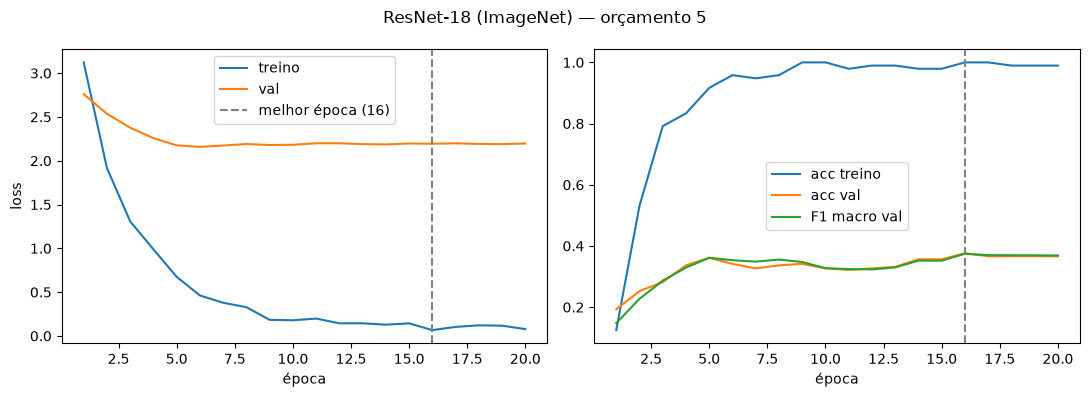

época com menor loss de val: 6 | melhor F1 val: 16


In [5]:
h = pd.DataFrame(hist_b)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h.epoch, h.train_loss, label="treino"); ax[0].plot(h.epoch, h.val_loss, label="val")
ax[0].axvline(ep_b, ls="--", c="gray", label=f"melhor época ({ep_b})"); ax[0].set(xlabel="época", ylabel="loss"); ax[0].legend()
ax[1].plot(h.epoch, h.train_acc, label="acc treino"); ax[1].plot(h.epoch, h.val_acc, label="acc val")
ax[1].plot(h.epoch, h.val_f1, label="F1 macro val"); ax[1].axvline(ep_b, ls="--", c="gray")
ax[1].set(xlabel="época"); ax[1].legend()
fig.suptitle("ResNet-18 (ImageNet) — orçamento 5"); fig.tight_layout()
fig.savefig(OUT / f"resnet18_b{BUDGET}_s{SEED}_curvas.png", dpi=120); plt.show()
print("época com menor loss de val:", int(h.val_loss.idxmin()) + 1, "| melhor F1 val:", int(h.val_f1.idxmax()) + 1)
h.to_csv(OUT / f"resnet18_b{BUDGET}_s{SEED}_history.csv", index=False)
pd.DataFrame(hist_a).to_csv(OUT / f"scratch_b{BUDGET}_s{SEED}_history.csv", index=False)

## Resultados no `test_public` (medido uma única vez)

In [6]:
ta = C.evaluate(model_a, test_dl, "cpu", NC)
tb = C.evaluate(model_b, test_dl, "cpu", NC)
res = pd.DataFrame({
    "modelo": ["(a) CNN do zero", "(b) ResNet-18 ImageNet + FT"],
    "parâmetros": [C.count_params(model_a), C.count_params(model_b)],
    "época (val)": [ep_a, ep_b],
    "F1 macro": [ta["f1_macro"], tb["f1_macro"]],
    "acurácia": [ta["acc"], tb["acc"]],
}).round(4)
res

,modelo,parâmetros,época (val),F1 macro,acurácia
0,(a) CNN do zero,1170869,31,0.1312,0.1529
1,(b) ResNet-18 ImageNet + FT,11187285,16,0.4377,0.4538


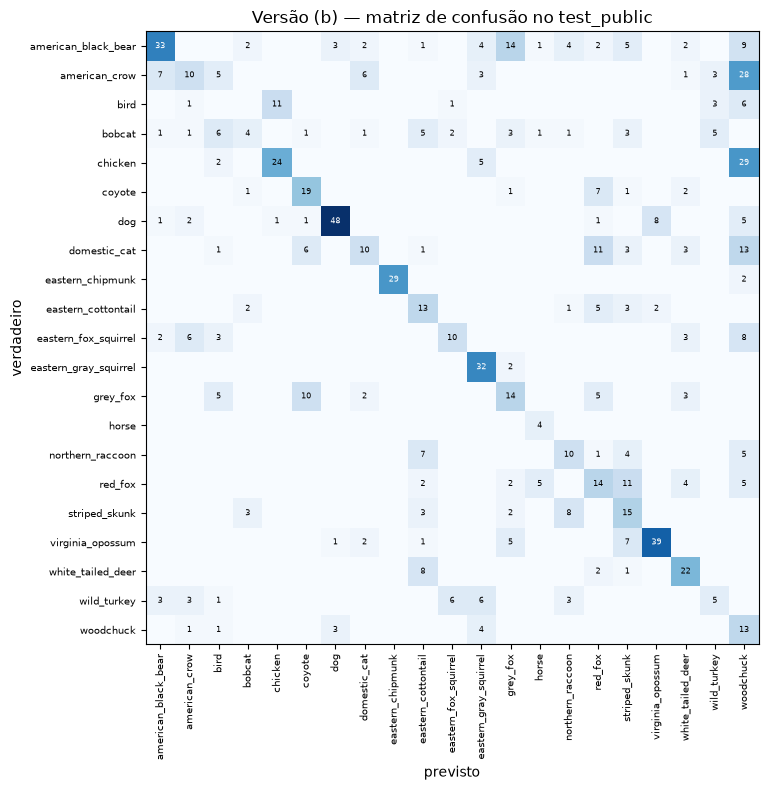

                       precision    recall  f1-score   support

  american_black_bear       0.70      0.40      0.51        82
        american_crow       0.42      0.16      0.23        63
                 bird       0.00      0.00      0.00        22
               bobcat       0.33      0.12      0.17        34
              chicken       0.67      0.40      0.50        60
               coyote       0.51      0.61      0.56        31
                  dog       0.87      0.72      0.79        67
         domestic_cat       0.43      0.21      0.28        48
     eastern_chipmunk       1.00      0.94      0.97        31
   eastern_cottontail       0.32      0.50      0.39        26
 eastern_fox_squirrel       0.53      0.31      0.39        32
eastern_gray_squirrel       0.59      0.94      0.73        34
             grey_fox       0.33      0.36      0.34        39
                horse       0.36      1.00      0.53         4
     northern_raccoon       0.37      0.37      0.37  

In [7]:
cm = confusion_matrix(tb["y"], tb["pred"], labels=list(range(NC)))
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NC), names, rotation=90, fontsize=7); ax.set_yticks(range(NC), names, fontsize=7)
for i in range(NC):
    for j in range(NC):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6, color="white" if cm[i, j] > cm.max()/2 else "black")
ax.set(xlabel="previsto", ylabel="verdadeiro", title="Versão (b) — matriz de confusão no test_public")
fig.tight_layout(); fig.savefig(OUT / f"resnet18_b{BUDGET}_s{SEED}_confusao.png", dpi=120); plt.show()
print(classification_report(tb["y"], tb["pred"], labels=list(range(NC)), target_names=names, zero_division=0))

## Salvando pesos e números (base da Parte 2)

In [8]:
torch.save(state_a, OUT / f"scratch_b{BUDGET}_s{SEED}.pt")
torch.save(state_b, OUT / f"resnet18_b{BUDGET}_s{SEED}.pt")

cb = ROOT / "curva_orcamento.csv"
rows = pd.read_csv(cb) if cb.exists() else pd.DataFrame(columns=["metodo", "orcamento", "seed", "f1_macro", "acuracia"])
novas = pd.DataFrame([
    ["piso_scratch",  BUDGET, SEED, round(ta["f1_macro"], 4), round(ta["acc"], 4)],
    ["piso_resnet18", BUDGET, SEED, round(tb["f1_macro"], 4), round(tb["acc"], 4)]], columns=rows.columns)
rows = rows[~((rows.metodo.isin(novas.metodo)) & (rows.orcamento == BUDGET) & (rows.seed == SEED))]
pd.concat([rows, novas]).to_csv(cb, index=False)
pd.read_csv(cb)

,metodo,orcamento,seed,f1_macro,acuracia
0,piso_scratch,5,0,0.1312,0.1529
1,piso_resnet18,5,0,0.4377,0.4538


### Comparação: CNN v1 (original) vs CNN atual
Baseline guardado em `results/parte0/baseline_cnn_v1/` (tempo informado pelo usuário, não cronometrado em código).

In [9]:
base = json.load(open(OUT / "baseline_cnn_v1" / "baseline.json", encoding="utf8"))
json.dump({"scratch_min": time_a/60, "resnet18_min": time_b/60}, open(OUT / "tempos_min.json", "w"))
pd.DataFrame([
    ["CNN v1 (original)", base["parametros"], base["tempo_treino_min"], base["test_f1_macro"], base["test_acuracia"]],
    ["CNN atual (stem stride 2)", C.count_params(model_a), round(time_a/60, 1), round(ta["f1_macro"], 4), round(ta["acc"], 4)],
], columns=["modelo", "parâmetros", "tempo (min)", "F1 macro test", "acurácia test"])

,modelo,parâmetros,tempo (min),F1 macro test,acurácia test
0,CNN v1 (original),1178613,28.0,0.1411,0.1973
1,CNN atual (stem stride 2),1170869,5.9,0.1312,0.1529


### Ajuste do piso (b) — escolhido só no `val`

O piso (b) usou hiperparâmetros sem comparação. Aqui testamos resolução (224 vs 320 px) e learning rate (3e-4 vs 1e-3),
sempre com o orçamento de 5 rótulos e a mesma seed. **Nenhuma decisão olha o `test_public`**: a configuração vencedora é a de maior F1 macro no `val`.
A busca é retomável: configurações já medidas em `results/parte0/tuning_val.csv` são puladas.

In [13]:
import time
EPOCHS_TUNE = 15
GRID = [(224, 3e-4), (224, 1e-3), (320, 3e-4), (320, 1e-3)]
tune_path = OUT / "tuning_val.csv"
tune = pd.read_csv(tune_path) if tune_path.exists() else pd.DataFrame(
    columns=["img_size", "lr", "best_epoch", "val_f1", "val_acc", "val_loss", "min_val_loss_epoch", "min"])
cache = {}
for size, lr in GRID:
    if ((tune.img_size == size) & (np.isclose(tune.lr, lr))).any():
        print("já medido:", size, lr); continue
    if size not in cache:
        cache[size] = (C.CachedImages(train_items, c2i, True, size), C.CachedImages(C.read_split("val.csv", "val"), c2i, False, size))
    tr_ds, va_ds = cache[size]
    g = torch.Generator().manual_seed(SEED)
    C.set_seed(SEED)
    m = C.resnet18(NC, pretrained=True)
    t0 = time.perf_counter()
    hist, ep, state = C.fit(m, DataLoader(tr_ds, BS, shuffle=True, drop_last=True, generator=g), DataLoader(va_ds, 64),
                            EPOCHS_TUNE, lr=lr, num_classes=NC, verbose=False)
    h = pd.DataFrame(hist)
    row = dict(img_size=size, lr=lr, best_epoch=ep, val_f1=h.val_f1.max(), val_acc=h.val_acc[h.val_f1.idxmax()],
               val_loss=h.val_loss[h.val_f1.idxmax()], min_val_loss_epoch=int(h.val_loss.idxmin()) + 1,
               min=round((time.perf_counter() - t0) / 60, 1))
    print(row, flush=True)
    tune = pd.concat([tune, pd.DataFrame([row])], ignore_index=True)
    tune.to_csv(tune_path, index=False)
tune.sort_values("val_f1", ascending=False).round(4)

TypeError: CachedImages.__init__() takes 4 positional arguments but 5 were given

Com a configuração vencedora (maior F1 no `val`) treinamos de novo e medimos o `test_public` **uma única vez**.
Os resultados entram no `curva_orcamento.csv` como `piso_resnet18_tuned`, ao lado do piso original.

In [ ]:
bst = tune.sort_values("val_f1", ascending=False).iloc[0]
SIZE_B, LR_B, EP_B = int(bst.img_size), float(bst.lr), EPOCHS_TUNE
print("configuração escolhida (val):", dict(img_size=SIZE_B, lr=LR_B))
tr_ds = C.CachedImages(train_items, c2i, True, SIZE_B)
va_ds = C.CachedImages(C.read_split("val.csv", "val"), c2i, False, SIZE_B)
te_ds = C.CachedImages(C.read_split("test_public.csv", "test_public"), c2i, False, SIZE_B)
C.set_seed(SEED)
model_t = C.resnet18(NC, pretrained=True)
hist_t, ep_t, state_t = C.fit(model_t, DataLoader(tr_ds, BS, shuffle=True, drop_last=True,
                              generator=torch.Generator().manual_seed(SEED)), DataLoader(va_ds, 64), EP_B, lr=LR_B, num_classes=NC)
model_t.load_state_dict(state_t)
tt = C.evaluate(model_t, DataLoader(te_ds, 64), "cpu", NC)
torch.save(state_t, OUT / f"resnet18_tuned_b{BUDGET}_s{SEED}.pt")
pd.DataFrame(hist_t).to_csv(OUT / f"resnet18_tuned_b{BUDGET}_s{SEED}_history.csv", index=False)

cb = ROOT / "curva_orcamento.csv"
rows = pd.read_csv(cb)
rows = rows[~((rows.metodo == "piso_resnet18_tuned") & (rows.orcamento == BUDGET) & (rows.seed == SEED))]
rows = pd.concat([rows, pd.DataFrame([["piso_resnet18_tuned", BUDGET, SEED, round(tt["f1_macro"], 4), round(tt["acc"], 4)]], columns=rows.columns)])
rows.to_csv(cb, index=False)
print(f"época (val): {ep_t} | test_public: F1 macro {tt['f1_macro']:.4f}  acurácia {tt['acc']:.4f}")
pd.read_csv(cb)